# Day 93 – Model Training & Comparison

Today, I will train multiple Machine Learning classification models on the Loan Approval Prediction dataset.

The goal is to train different algorithms, compare their performance, and identify which model performs better on the loan approval prediction task.

Models to be explored:
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier
- Support Vector Machine (SVM)

The models will be evaluated and compared using performance metrics to select a suitable model for further improvement.

#Import libraries & upload dataset

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score

from google.colab import files

uploaded = files.upload()

print("Libraries imported successfully!")

Saving train_u6lujuX_CVtuZ9i (1).csv to train_u6lujuX_CVtuZ9i (1).csv
Libraries imported successfully!


In [2]:
df = pd.read_csv("train_u6lujuX_CVtuZ9i (1).csv")

# Separate features and target
X = df.drop(columns=["Loan_ID", "Loan_Status"])
y = df["Loan_Status"]

# Identify column types
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()

print("Dataset Shape:", df.shape)
print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Dataset Shape: (614, 13)
Numerical Columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical Columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


#Train-Test Split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (491, 11)
Testing Shape: (123, 11)


#Preprocessing Pipeline

In [4]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [5]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [6]:
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessor ready!")

Preprocessor ready!


In [9]:
def create_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ])

    return preprocessor

print("Preprocessor function created successfully!")

Preprocessor function created successfully!


In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", RandomForestClassifier(n_estimators=200, random_state=42))
    ]),

    "SVM": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", SVC())
    ])
}

print("All 4 models are ready for training!")
print("Models:", list(models.keys()))

All 4 models are ready for training!
Models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM']


In [11]:
results = []

for name, pipeline in models.items():
    # Train the model
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(f"{name} trained successfully | Accuracy: {accuracy:.4f}")

# Create comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Accuracy", ascending=False)

results_df

Logistic Regression trained successfully | Accuracy: 0.8618
Decision Tree trained successfully | Accuracy: 0.7561
Random Forest trained successfully | Accuracy: 0.8211
SVM trained successfully | Accuracy: 0.8537


,Model,Accuracy
0,Logistic Regression,0.861789
3,SVM,0.853659
2,Random Forest,0.821138
1,Decision Tree,0.756098


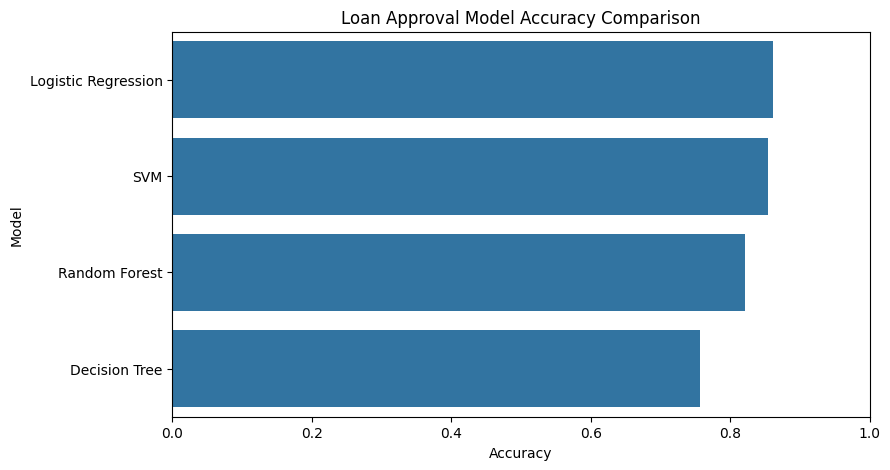

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(data=results_df, x="Accuracy", y="Model")

plt.title("Loan Approval Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

## Day 93 – Model Training & Comparison Conclusion

##In this session, four machine learning classification models were trained for the Loan Approval Prediction project: Logistic Regression, Decision Tree, Random Forest, and Support Vector Machine (SVM). All models were trained using a preprocessing pipeline that handled missing values, scaled numerical features, and encoded categorical variables. Their performance was compared using accuracy score.

##Logistic Regression achieved the highest accuracy of **86.18%**, followed by SVM with 85.37%, Random Forest with 82.11%, and Decision Tree with 75.61%. The results were visualized using a bar chart for better comparison. Logistic Regression was identified as the best-performing model based on initial accuracy. However, further evaluation using precision, recall, F1-score, and confusion matrix will be performed to determine the most suitable model.

#**Day 93 Status: Completed**